<a href="https://colab.research.google.com/github/Alejandra300905/NLP_Polarity_of_film_reviews_and_the_problem_of_negation/blob/main/ProyectoClasificacionR_AlejandraB_CarlosM_NatalieL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# R3.1 Polaridad de reseñas de cine y el problema de la negación

### Etapa 1 - **Análisis, representacion y baseline.** Limpieza (etiquetas HTML, puntuación) y división Train, Dev y Test. Baseline: bolsa de palabras de unigramas + Bayes ingenuo

tablita


In [24]:
import os
import tarfile
import urllib.request
import pandas as pd

# Descargar y extraer el archivo tar.gz si no se ha hecho ya
if not os.path.exists('aclImdb'):
    tar_filename = 'aclImdb_v1..gtarz'
    url = 'https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz'
    if not os.path.exists(tar_filename):
        print(f"Descargando {tar_filename}...")
        urllib.request.urlretrieve(url, tar_filename)

    print("Extrayendo aclImdb_v1.tar.gz...")
    with tarfile.open(tar_filename, 'r:gz') as tar:
        tar.extractall()

def load_imdb_dataset(base_dir):
    data = []
    for split in ['train', 'test']:
        for sentiment in ['pos', 'neg']:
            folder = os.path.join(base_dir, split, sentiment)
            label = 1 if sentiment == 'pos' else 0
            if os.path.exists(folder):
                for filename in os.listdir(folder):
                    if filename.endswith('.txt'):
                        with open(os.path.join(folder, filename), 'r', encoding='utf-8') as f:
                            review = f.read()
                            data.append({'review': review, 'sentiment': label, 'split': split})
    return pd.DataFrame(data)

# Cargar los datos en un DataFrame
df = load_imdb_dataset('aclImdb')

# Mostrar información general del DataFrame
print(f"Dimensiones del DataFrame: {df.shape}")
display(df.head())

Dimensiones del DataFrame: (50000, 3)


,review,sentiment,split
0,When I was a little girl (and my dad owned a v...,1,train
1,This is a great adaptation and a great miniser...,1,train
2,The first thing you meet when you study fascis...,1,train
3,"Okay, okay, maybe not THE greatest. I mean, Th...",1,train
4,"""Victor doesn't have much, but that's not stop...",1,train


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  int64 
 2   split      50000 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.1+ MB


In [26]:
df.split.values

array(['train', 'train', 'train', ..., 'test', 'test', 'test'],
      dtype=object)

In [27]:
# Mostrar los valores únicos y la cantidad de registros para cada split
display(df['split'].value_counts())

,count
split,
train,25000
test,25000


In [28]:
# Mostrar algunas reseñas de ejemplo completas
print("Ejemplo de Reseña Positiva:")
print(df[df['sentiment'] ==1 ]['review'].iloc[0])
print("\n" + "="*80 + "\n")
print("Ejemplo de Reseña Negativa:")
print(df[df['sentiment'] == 0]['review'].iloc[0])


Ejemplo de Reseña Positiva:
When I was a little girl (and my dad owned a video store), this was among my favorite movies. I hadn't heard much about it since then, nor did I really remember anything about it, it having been forgotten in the wake of Don Bluth's other, probably better films. I managed to track it down a few weeks ago, however, and was pleasantly surprised again. Set in New Orleans in the 1930s, the animation is delightful and the songs are memorable. There are a few goofs in continuity if you look hard enough, but they generally don't detract from the storyline, which leaves you smiling (and maybe even a little misty-eyed, if you are a lover of animals). The characters are believable (maybe even a little too grown-up for younger watchers), as well. Two paws up, and for those of you who haven't seen it in a while, definitely worth a re-watch.


Ejemplo de Reseña Negativa:
How do you spell washed up fat Italian who can barely pull off a martial arts move without needing som

## Positiva
- En: This is a gem of a movie not just for people who like fun and quirky premises, but who love the history and traditions of Sci-Fi and Classic Hollywood movies. Each alien of the Martian crew is the embodiment of a classic Sci-Fi character or member of Hollywood royalty and it's pure pleasure watching them bounce of each other and the residents of Big Bean.
---
- Es: Esta película es una auténtica joya, no solo para quienes disfrutan de premisas divertidas y peculiares, sino también para los amantes de la historia y las tradiciones de la ciencia ficción y el cine clásico de Hollywood. Cada alienígena de la tripulación marciana encarna a un personaje clásico de la ciencia ficción o a una figura emblemática de Hollywood; es un verdadero placer ver cómo interactúan entre ellos y con los habitantes de Big Bean.

## Negativa
- En: 'Anita and Me' is a drama about growing up in multi-ethnic Britain, rather like 'Bend it Like Beckham', or more closely, 'East is East', with which it shares a 1970s setting. The tone is resolutely chirpy (in spite of the dour Black Country accents), but the film lacks 'East is East's vigour and the result seems rather thin and trite. Moreover, the portrayal of the film's central relationship, between an Asian girl and her white friend, is insufficiently deep to justify the way that the movie is structured around it. I have also grown tired of films where the hero years to be a writer, this is naturally often something that real writers have experienced, but hardly a fresh element in a fictional story. 'East is East' was fun and sharp; 'Anita and Me' seems obvious and dull in comparison.

---
- Es: «Anita and Me» es un drama sobre el proceso de madurar en una Gran Bretaña multiétnica; recuerda a «Bend It Like Beckham» o, más aún, a «East Is East», con la que comparte una ambientación en la década de 1970. El tono es decididamente alegre (a pesar de los ásperos acentos de la región de Black Country), pero a la película le falta el vigor de «East Is East», por lo que el resultado parece bastante superficial y trillado. Además, el retrato de la relación central —entre una chica de origen asiático y su amiga blanca— carece de la profundidad necesaria para justificar que la película se estructure en torno a ella. Por otra parte, ya me han cansado las películas en las que el protagonista anhela convertirse en escritor; si bien es algo que muchos escritores han vivido en la realidad, no deja de ser un recurso poco original en una obra de ficción. «East Is East» era divertida e ingeniosa; en comparación, «Anita and Me» resulta predecible y aburrida.

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: n_palabras, dtype: float64


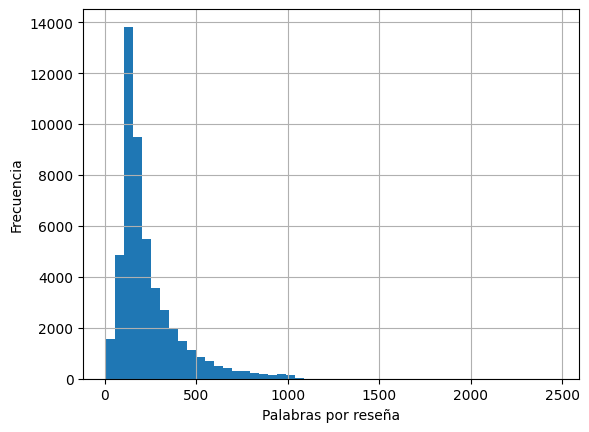

Con <br />: 29200


In [29]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# Balance de clases y tamaño de cada partición
#print(df.groupby(["split", "sentiment"]).size().unstack())

# Longitud de reseñas (en palabras)
df["n_palabras"] = df["review"].str.split().str.len()
print(df["n_palabras"].describe())

df["n_palabras"].hist(bins=50)
plt.xlabel("Palabras por reseña"); plt.ylabel("Frecuencia")
plt.show()

# ¿Cuántas reseñas tienen etiquetas HTML?
print("Con <br />:", df["review"].str.contains("<br", regex=False).sum())

In [30]:
# Encontrar los índices de las reseñas con menos y más palabras
idx_min = df['n_palabras'].idxmin()
idx_max = df['n_palabras'].idxmax()

print(f"=== RESEÑA CON MENOS PALABRAS ({df.loc[idx_min, 'n_palabras']} palabras) ===")
print(f"Sentiment: {'Positivo' if df.loc[idx_min, 'sentiment'] == 1 else 'Negativo'}")
print(df.loc[idx_min, 'review'])
print("\n" + "="*50 + "\n")

print(f"=== RESEÑA CON MÁS PALABRAS ({df.loc[idx_max, 'n_palabras']} palabras) ===")
print(f"Sentiment: {'Positivo' if df.loc[idx_max, 'sentiment'] == 1 else 'Negativo'}")
# Mostramos los primeros 1500 caracteres para no saturar la pantalla, pero se puede imprimir completa
print(df.loc[idx_max, 'review'][:1500] + '\n... [TRUNCADO]')


=== RESEÑA CON MENOS PALABRAS (4 palabras) ===
Sentiment: Negativo
Primary plot!Primary direction!Poor interpretation.


=== RESEÑA CON MÁS PALABRAS (2470 palabras) ===
Sentiment: Positivo
Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag Team Table Match against Eddie Guerrero and Chris Benoit. According to the rules of the match, both opponents have to go through tables in order to get the win. Benoit and Guerrero heated up early on by taking turns hammering first Spike and then Bubba Ray. A German suplex by Benoit to Bubba took the wind out of the Dudley brother. Spike tried to help his brother, but the referee restrained him while Benoit and Guerrero ganged up on him in the corner. With Benoit stomping away on Bubba, Guerrero set up a table outside. Spike dashed into the ring and somersaulted over the top rope onto Guerrero on the outside! After recovering and taking care of Spike, Gu

In [31]:
def limpiar(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)      # quita etiquetas HTML
    texto = texto.lower()                        # minúsculas
    texto = re.sub(r"[^a-z' ]", " ", texto)      # quita puntuación, números y símbolos (conserva ')
    texto = re.sub(r"\s+", " ", texto).strip()   # colapsa espacios
    return texto

df["clean"] = df["review"].apply(limpiar)
print(df.loc[0, "review"][:200])
print(df.loc[0, "clean"][:200])

When I was a little girl (and my dad owned a video store), this was among my favorite movies. I hadn't heard much about it since then, nor did I really remember anything about it, it having been forgo
when i was a little girl and my dad owned a video store this was among my favorite movies i hadn't heard much about it since then nor did i really remember anything about it it having been forgotten i


In [32]:
df.head()

,review,sentiment,split,n_palabras,clean
0,When I was a little girl (and my dad owned a v...,1,train,152,when i was a little girl and my dad owned a vi...
1,This is a great adaptation and a great miniser...,1,train,605,this is a great adaptation and a great miniser...
2,The first thing you meet when you study fascis...,1,train,237,the first thing you meet when you study fascis...
3,"Okay, okay, maybe not THE greatest. I mean, Th...",1,train,964,okay okay maybe not the greatest i mean the ex...
4,"""Victor doesn't have much, but that's not stop...",1,train,248,victor doesn't have much but that's not stoppi...


In [33]:
train_full = df[df["split"] == "train"]
test = df[df["split"] == "test"]      # se queda intacto hasta el final

train, dev = train_test_split(
    train_full,
    test_size=0.2,
    stratify=train_full["sentiment"],
    random_state=42
)

print(len(train), len(dev), len(test))   # 20000, 5000, 25000

20000 5000 25000


In [34]:
vectorizer = CountVectorizer(
    ngram_range=(1,1),
    token_pattern=r"[a-z]+(?:'[a-z]+)*",   # conserva didn't, isn't...
    min_df=2
)
X_train = vectorizer.fit_transform(train["clean"])   # fit SOLO con train
X_dev   = vectorizer.transform(dev["clean"])
X_test  = vectorizer.transform(test["clean"])

y_train, y_dev, y_test = train["sentiment"], dev["sentiment"], test["sentiment"]
print("Vocabulario:", len(vectorizer.vocabulary_))

nb = MultinomialNB(alpha=1.0)
nb.fit(X_train, y_train)

Vocabulario: 42786


MultinomialNB()

In [35]:
print(X_train[:3])

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 398 stored elements and shape (3, 42786)>
  Coords	Values
  (0, 18333)	6
  (0, 20439)	1
  (0, 32941)	1
  (0, 38187)	9
  (0, 13843)	9
  (0, 38363)	1
  (0, 38679)	1
  (0, 19452)	1
  (0, 13721)	1
  (0, 13391)	1
  (0, 26438)	11
  (0, 16664)	2
  (0, 16961)	3
  (0, 41875)	1
  (0, 26056)	2
  (0, 2985)	3
  (0, 10352)	1
  (0, 1240)	12
  (0, 18429)	2
  (0, 42553)	1
  (0, 1714)	1
  (0, 13356)	1
  (0, 42028)	1
  (0, 10311)	1
  (0, 26436)	1
  :	:
  (2, 17577)	1
  (2, 2729)	1
  (2, 5820)	1
  (2, 41027)	1
  (2, 37643)	1
  (2, 3878)	1
  (2, 22044)	1
  (2, 9573)	1
  (2, 5332)	1
  (2, 36675)	1
  (2, 3191)	1
  (2, 22564)	1
  (2, 157)	1
  (2, 6749)	1
  (2, 17055)	1
  (2, 2626)	1
  (2, 3298)	1
  (2, 12319)	1
  (2, 41667)	1
  (2, 25828)	1
  (2, 22140)	1
  (2, 14159)	1
  (2, 9860)	1
  (2, 8778)	1
  (2, 31389)	1


In [36]:
# Tomamos el texto limpio de la primera fila del conjunto de train como ejemplo
ejemplo_texto = train["clean"].iloc[2]
ejemplo_vectorizado = X_train[2]

print("Texto original limpio:")
print(ejemplo_texto)
print("\n" + "="*50 + "\n")

print("Representación en la Matriz Dispersa (Sparse Matrix) - (Fila, ID_Vocabulario) Frecuencia:")
print(ejemplo_vectorizado)
print("\n" + "="*50 + "\n")

# Mapeamos los IDs de vuelta a las palabras correspondientes del vocabulario
print("Palabras presentes en este texto y sus frecuencias:")
nombres_caracteristicas = vectorizer.get_feature_names_out()
coordenadas = ejemplo_vectorizado.tocoo()
for col, val in zip(coordenadas.col, coordenadas.data):
    print(f"- '{nombres_caracteristicas[col]}' (ID: {col}): {val} vez/veces")


Texto original limpio:
my girlfriend and i have a thing for robots so i try to seek out movies that have robots and this movie has robots big ones they beat the clang and bang out of each other with the fate of nations hanging in the balance it's really cool you have to forgive this movie its many shortcomings and just try to appreciate what the director and his crew of technicians were able to put on the screen while working with what was obviously a tight budget it is very hard to dislike this movie because of those big robots they looked like transformers and they fought like pro wrestlers it made my girlfriend smile and that is good enough for me and special mention must be made of veteran character actor paul koslo as the maniacal russian villain whether he is ruthlessly stomping on his helpless opponents after they've already surrendered or complaining that their close proximity to him in a bar has caused his vodka to taste like blood a line he delivers with a deliciously campy s

In [37]:
def evaluar(modelo, X, y, nombre):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    print(f"── {nombre} ──")
    print(f"Exactitud: {accuracy_score(y, pred):.4f}")
    print(f"F1:        {f1_score(y, pred):.4f}")
    print(f"AUC-ROC:   {roc_auc_score(y, proba):.4f}")
    return pred

pred_dev = evaluar(nb, X_dev, y_dev, "Dev")
print(classification_report(y_dev, pred_dev, target_names=["neg", "pos"]))

# Test: úsalo UNA sola vez, cuando el baseline esté definitivo
pred_test = evaluar(nb, X_test, y_test, "Test")

── Dev ──
Exactitud: 0.8536
F1:        0.8489
AUC-ROC:   0.9245
              precision    recall  f1-score   support

         neg       0.83      0.88      0.86      2500
         pos       0.88      0.82      0.85      2500

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000

── Test ──
Exactitud: 0.8143
F1:        0.8016
AUC-ROC:   0.8926


In [38]:
# Seleccionamos una reseña del conjunto de desarrollo (por ejemplo, la primera)
indice_ejemplo = 0
texto_original = dev["review"].iloc[indice_ejemplo]
texto_limpio = dev["clean"].iloc[indice_ejemplo]
etiqueta_real = dev["sentiment"].iloc[indice_ejemplo]

# Transformamos el texto con el vectorizer para que tenga el formato adecuado
vector_ejemplo = X_dev[indice_ejemplo]

# Obtenemos las probabilidades de cada clase
probabilidades = nb.predict_proba(vector_ejemplo)[0]
prediccion = nb.predict(vector_ejemplo)[0]

print("=== TEXTO DE LA RESEÑA ===")
print(texto_original[:500] + ("..." if len(texto_original) > 500 else ""))
print("\n" + "="*30)
print(f"Etiqueta Real: {'Positivo (1)' if etiqueta_real == 1 else 'Negativo (0)'}")
print(f"Predicción del Modelo: {'Positivo (1)' if prediccion == 1 else 'Negativo (0)'}")
print("="*30)
print(f"Probabilidad de ser NEGATIVA (0): {probabilidades[0]:.6f} ({probabilidades[0]*100:.4f}%)")
print(f"Probabilidad de ser POSITIVA (1): {probabilidades[1]:.6f} ({probabilidades[1]*100:.4f}%)")


=== TEXTO DE LA RESEÑA ===
The movie takes place in a little Swedish town where everybody knows each other. Here Mia visits her parent for the birthday of her father, a which occasionally always have some kind of tragedy, the question is just what will it be this year, and you will be surprised... It is an extremely well composed movie, with a story which has a perfect balance of humor and seriousness, which is rarely seen. You get happy, you get hurt, and basically everything in between. Finally you can't help falling in...

Etiqueta Real: Positivo (1)
Predicción del Modelo: Positivo (1)
Probabilidad de ser NEGATIVA (0): 0.000290 (0.0290%)
Probabilidad de ser POSITIVA (1): 0.999710 (99.9710%)


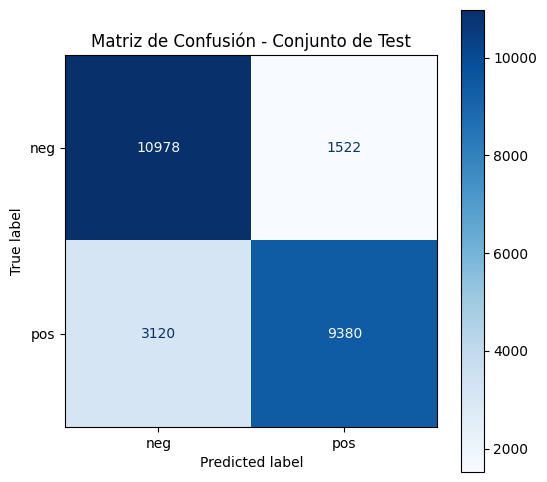

Verdaderos Negativos (TN): 10978
Falsos Positivos (FP): 1522
Falsos Negativos (FN): 3120
Verdaderos Positivos (TP): 9380


In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcular la matriz de confusión usando las etiquetas reales de test (y_test) y las predicciones (pred_test)
cm = confusion_matrix(y_test, pred_test)

# Crear la visualización de la matriz de confusión
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"])

# Graficar la matriz
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
plt.title("Matriz de Confusión - Conjunto de Test")
plt.show()

# Imprimir también los valores numéricos directos
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos Negativos (TN): {tn}")
print(f"Falsos Positivos (FP): {fp}")
print(f"Falsos Negativos (FN): {fn}")
print(f"Verdaderos Positivos (TP): {tp}")


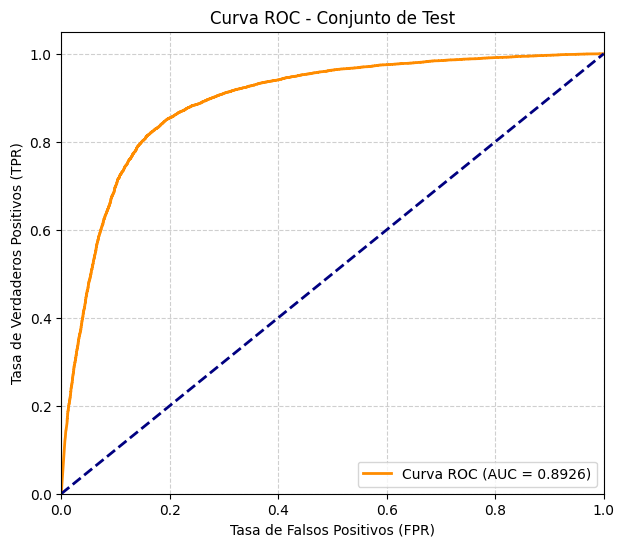

In [40]:
from sklearn.metrics import roc_curve, auc

# Obtener las probabilidades de pertenecer a la clase positiva (1) para el conjunto de test
proba_test = nb.predict_proba(X_test)[:, 1]

# Calcular la tasa de verdaderos positivos (tpr) y la tasa de falsos positivos (fpr)
fpr, tpr, _ = roc_curve(y_test, proba_test)
roc_auc = auc(fpr, tpr)

# Graficar la curva ROC
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Conjunto de Test')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
